# Nearest Neighbors: Geometry, Local Estimation, and Retrieval

## 1. Introduction and learning objectives

Nearest-neighbor methods store examples and make predictions by comparing a new observation with nearby stored observations. The central modeling choice is what **nearby** means. This chapter develops local prediction, metric/scaling assumptions, deterministic ties, computational cost, validation, and the limits of asymptotic guarantees.

Prerequisites are Stage 01 evaluation and the Stage 02 information/decision chapter. You will implement exact search, classification and regression in NumPy without allocating a complete query×training×feature tensor. The same geometric questions reappear in learned embeddings and retrieval; learning a representation and searching an existing representation are separate computations.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.02.01 — Identify what is learned and what is assumed

**Type:** Conceptual · **Answer:** Markdown

A classifier stores every labeled training row and uses the nearest row's label. Identify its fitted state, prediction computation, assumptions about distance, and parameters that require selection. Why can a very short fitting time coexist with expensive prediction?

**Expected outcome:** describe data storage, preprocessing, search, and statistical assumptions separately.

**Your response to Exercise 02.02.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.01**

Count work when a query arrives, not only when a training API is called.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.01**

State includes stored features/labels and any training-fitted transformation. Prediction computes distances and retrieves a neighborhood. The rule assumes the chosen geometry makes nearby observations informative about the target; feature units, irrelevant coordinates, and population changes can violate that assumption. Select k, distance/weighting policy, and preprocessing within the declared protocol. Storing rows can be cheap while comparing each query with many rows is expensive. A fitted representation, if used, has an additional training cost.

</details>

## 2. Prerequisites and mathematical foundations

For query x∈R^d and training rows x_i, Euclidean squared distance is d_i²=Σ_j(x_j−x_ij)². Squaring preserves Euclidean neighbor order. Manhattan distance Σ_j|x_j−x_ij| can produce a different order. Multiplying a feature by 100 changes its contribution to squared distance by 10000. Standardization estimates location/scale from training rows; it changes geometry and is not universally optimal.

Let N_k(x) contain the k nearest row indices. Uniform kNN regression predicts their target mean. With nonnegative normalized weights a_i, it predicts Σ_i a_i y_i, the minimizer of Σ_i a_i(y_i−c)². Uniform classification estimates local class frequencies; choosing the most frequent class minimizes weighted empirical zero-one loss. These local frequencies are estimates, not guaranteed calibrated conditional probabilities. Finite k can assign zero probability to a class that remains possible.

We resolve equal distances by smaller training-row index and equal class votes by smaller class label. Exact duplicate features can have conflicting targets; the rule must specify how a selected neighborhood handles them. The reference's inverse-distance weighting uses only selected zero-distance neighbors when any exist, averaging among those selected exact matches. If more than k exact matches exist, the distance-tie policy still matters.

## 3. Theoretical development and worked examples

### A hand-checkable neighborhood

Training coordinates are [0,2,4,6], class labels [0,1,1,0], and query x=3. Squared distances are [9,1,1,9]. With index tie breaking, k=1 selects index 1, and k=3 selects indices [1,2,0]. Uniform class probabilities for k=3 are [1/3,2/3]. Inverse Euclidean-distance weights are proportional to [1,1,1/3], giving probabilities [1/7,6/7]. Inverse squared distance is a different weighting policy.

If regression targets instead equal [0,2,4,6], uniform k=3 predicts 2 and inverse-distance weighting predicts 18/7. At query x=2, inverse-distance weighting uses the selected exact match, avoiding division by zero and predicting its target 2.

### Exercise 02.02.02 — Change the metric and the neighborhood

**Type:** Numerical · **Answer:** Markdown

Verify the worked k=3 predictions. Then compare the nearest point to the origin among (3,0) and (2,2) under Manhattan and Euclidean distance. State every tie and weighting convention used.

**Expected outcome:** exact neighbor indices, class probabilities, regression values, and two different metric decisions.

**Your response to Exercise 02.02.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.02**

Normalize the inverse distances, not the squared inverse distances.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.02**

The worked indices are [1,2,0], with uniform regression mean (2+4+0)/3=2. Inverse-distance weights normalize to [3/7,3/7,1/7], giving regression 18/7 and class probabilities [1/7,6/7]. Manhattan distances to the two 2D points are 3 and 4, so choose (3,0). Euclidean distances are 3 and √8, so choose (2,2). A metric is a modeling choice, not just an implementation detail.

</details>

### Locality and dimension

For a uniform distribution on [−1,1]^d, the centered axis-aligned box of half-width r, 0≤r≤1, contains fraction r^d of the mass. To contain fraction f, r=f^(1/d). For f=.1 this is about .316 at d=2, .794 at d=10, and .955 at d=50. This particular example uses maximum-coordinate distance and uniform independent coordinates; it is not a theorem that every high-dimensional dataset behaves the same way. Low-dimensional structure and a useful learned geometry can change practical behavior.

Small k creates a highly local, variable estimate; larger k averages more labels but may mix different conditional distributions. The resulting bias/variance tradeoff depends on the generating process and metric. k=1 can have zero training error with unique rows while still making mistakes on new observations. Training-set self matches are not a valid generalization estimate.

### Exercise 02.02.03 — Derive two local prediction rules

**Type:** Mathematical · **Answer:** Markdown

Derive the weighted-mean regression predictor by differentiating weighted squared loss. Derive weighted majority classification by minimizing weighted zero-one loss. Assume nonnegative weights sum to one.

**Expected outcome:** both minimizers and the role of ties, without assuming the neighborhood frequencies equal population probabilities.

**Your response to Exercise 02.02.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.03**

For classification, minimizing one minus the weight assigned to the chosen class maximizes that class's weight.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.03**

For regression, derivative 2Σ_i a_i(c−y_i)=2(c−Σ_i a_i y_i) vanishes at the weighted mean, with curvature 2. For classification action c, loss is Σ_i a_i 1[y_i≠c]=1−Σ_(i:y_i=c)a_i. Any class with maximum total weight minimizes it; the implementation chooses the smallest label at a tie. These optimize local empirical objectives. Their population relevance depends on the neighborhood and sampling assumptions.

</details>

### Computational and numerical contracts

Brute-force distances require O(n_query n_train d) arithmetic and stored training data O(n_train d). A full distance matrix needs O(n_query n_train) storage; a broadcast difference tensor adds a factor d. The reference processes query and training blocks and retains only the best k candidates per query. Auxiliary storage is O(B_query B_train+B_query k), plus stored inputs and O(n_query k) returned neighbors. Sorting the merged block candidates adds sorting work; this reference favors exact deterministic ordering over the fastest top-k implementation.

The identity ||q||²+||x||²−2qᵀx can lose small distances through cancellation at large offsets. Here we accumulate coordinate differences directly, using one 2D block per coordinate. This still has floating-point limits and rejects nonfinite squared-distance results. Converting already rounded float32 inputs to float64 cannot restore lost coordinates.

## 4. Guided exercises

### Exercise 02.02.04 — Budget locality and memory

**Type:** Numerical · **Answer:** Markdown

Calculate the half-width needed for 10% mass in the uniform cube at d=2,10,50. Estimate bytes for 20000 queries, 100000 training rows, 32 features using a float64 broadcast difference tensor. Compare with a 32×128 distance block. Do not allocate the large tensor.

**Expected outcome:** the locality calculation and a bounded-memory design compatible with the laptop budget.

**Your response to Exercise 02.02.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.04**

The large tensor has query×training×feature entries. A distance block has only query-block×training-block entries, with several temporary copies during sorting.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.04**

Half-widths are .1^(1/d), approximately .316,.794,.955. The difference tensor alone needs 20000×100000×32×8=512,000,000,000 bytes, about 476.8 GiB. One 32×128 float64 distance block is 32768 bytes. Actual block search also stores differences, candidates, indices, and sort order, plus inputs/results. Chunking bounds memory but retains the full brute-force distance arithmetic and sorting overhead.

</details>

### Exercise 02.02.05 — Explain self-match leakage

**Type:** Conceptual · **Answer:** Markdown

A learner predicts each training row with k=1 using the same stored data and reports 100% accuracy. Another removes all zero-distance rows for leave-one-out evaluation. Explain both problems.

**Expected outcome:** distinguish the query's own row from different observations with identical features, and state preprocessing boundaries.

**Your response to Exercise 02.02.05**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.05**

Leave-one-out excludes an observation identity, not every observation at its coordinates.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.05**

The first evaluation usually retrieves the observation itself and measures memorization. Leave-one-out must exclude only the held-out row index; removing every exact duplicate discards legitimate other observations and changes the procedure. Preprocessing must also be fitted without that held-out row if it is part of the evaluated fitting procedure. Grouped duplicates from one source may require a group split rather than row-level leave-one-out. Conflicting duplicate labels make tie policies and sampling units especially relevant.

</details>

## 5. Implementation challenges

### Exercise 02.02.06 — Search exact neighbors with bounded blocks

**Type:** Programming · **Answer:** Code

Implement `neighbor_search(train,query,k,query_block=32,train_block=128)`. Return (indices,squared_distances) of shape (n_query,k), ordered by distance then training index. Allow an empty query matrix with the correct feature width. Validate k/block sizes, feature shapes, and finite values. Do not allocate a 3D difference tensor.

**Expected outcome:** hand-example agreement, deterministic ties, block-size invariance, no input mutation, and explicit failure when distances exceed floating-point range.

In [ ]:
# Your code for Exercise 02.02.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.06**

Keep the current top k, merge with one training block, and lexicographically sort using distance as the primary key.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.06**

The helper validates only feature arrays; classification/regression labels are checked by their respective functions. Direct coordinate accumulation avoids cancellation from the norm-expansion identity. At each step discarded candidates cannot enter the eventual global top k because at least k already-processed candidates precede them under the same total ordering.

~~~python
def neighbor_features(train, query):
    train, query = np.asarray(train, float), np.asarray(query, float)
    if train.ndim != 2 or min(train.shape) == 0 or query.ndim != 2 or query.shape[1] != train.shape[1]:
        raise ValueError("nonempty training rows and matching query feature width required")
    if not np.isfinite(train).all() or not np.isfinite(query).all():
        raise ValueError("finite features required")
    return train, query

def neighbor_search(train, query, k, query_block=32, train_block=128):
    train, query = neighbor_features(train, query)
    for value in (k, query_block, train_block):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError("positive integer k and block sizes required")
    if k > len(train):
        raise ValueError("k cannot exceed training size")
    result_indices = np.empty((len(query), k), dtype=int)
    result_distances = np.empty((len(query), k))
    for start in range(0, len(query), query_block):
        Q = query[start:start+query_block]
        best_d, best_i = np.empty((len(Q), 0)), np.empty((len(Q), 0), dtype=int)
        for offset in range(0, len(train), train_block):
            T = train[offset:offset+train_block]
            distance = np.zeros((len(Q), len(T)))
            with np.errstate(over='ignore', invalid='ignore'):
                for j in range(train.shape[1]):
                    difference = Q[:, j, None]-T[None, :, j]
                    distance += difference*difference
            if not np.isfinite(distance).all():
                raise FloatingPointError("squared distances exceed floating-point range")
            ids = np.broadcast_to(np.arange(offset, offset+len(T)), distance.shape)
            candidates_d = np.concatenate([best_d, distance], axis=1)
            candidates_i = np.concatenate([best_i, ids], axis=1)
            order = np.lexsort((candidates_i, candidates_d), axis=1)[:, :k]
            best_d = np.take_along_axis(candidates_d, order, axis=1)
            best_i = np.take_along_axis(candidates_i, order, axis=1)
        result_indices[start:start+len(Q)] = best_i
        result_distances[start:start+len(Q)] = best_d
    return result_indices, result_distances
~~~

</details>

### Exercise 02.02.07 — Normalize neighbor weights with exact matches

**Type:** Programming · **Answer:** Code

Implement `neighbor_weights(squared,mode='uniform')`. Support uniform or inverse Euclidean-distance weights. If a row has selected zero distances, give equal mass only to those exact matches. Require finite nonnegative (n_query,k) values with k≥1; preserve empty-query shape.

**Expected outcome:** normalized rows, the worked [3/7,3/7,1/7] weights, and no divide-by-zero warnings.

In [ ]:
# Your code for Exercise 02.02.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.07**

Handle rows with exact matches before computing reciprocal distances for other rows.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.07**

These weights describe a specified estimator. The zero-match rule is not a claim that duplicate labels are noise-free. It averages the selected exact matches, whose membership still follows the search's k/tie policy.

~~~python
def neighbor_weights(squared, mode='uniform'):
    squared = np.asarray(squared, float)
    if squared.ndim != 2 or squared.shape[1] == 0 or not np.isfinite(squared).all() or np.any(squared < 0):
        raise ValueError("finite nonnegative distance matrix with k >= 1 required")
    if mode == 'uniform':
        return np.full(squared.shape, 1/squared.shape[1])
    if mode != 'distance':
        raise ValueError("unknown weighting mode")
    zero = squared == 0; exact = zero.any(axis=1)
    result = np.empty_like(squared)
    if exact.any():
        result[exact] = zero[exact]/zero[exact].sum(axis=1, keepdims=True)
    if (~exact).any():
        inverse = 1/np.sqrt(squared[~exact])
        result[~exact] = inverse/inverse.sum(axis=1, keepdims=True)
    return result
~~~

</details>

### Exercise 02.02.08 — Implement multiclass local classification

**Type:** Programming · **Answer:** Code

Implement `knn_classify(train,labels,query,k,mode='uniform')`. Labels are an integer vector and need not be contiguous or start at zero. Return predictions, normalized class scores, and sorted observed classes. Equal class scores choose the smallest label. Validate target shape before search.

**Expected outcome:** binary hand values, three-class ordering, conflicting duplicates, and empty-query support.

In [ ]:
# Your code for Exercise 02.02.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.08**

Encode labels using np.unique(...,return_inverse=True), then accumulate each neighbor's weight into its class column.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.08**

This depends on `neighbor_features`, `neighbor_search`, and `neighbor_weights`. Returned columns correspond only to observed training classes; absence of a class is not evidence that its population probability is zero. The local scores require separate probability-quality evaluation.

~~~python
def knn_classify(train, labels, query, k, mode='uniform'):
    train, query = neighbor_features(train, query)
    labels = np.asarray(labels)
    if labels.shape != (len(train),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("one integer label per training row required")
    classes, encoded = np.unique(labels, return_inverse=True)
    indices, squared = neighbor_search(train, query, k)
    weights = neighbor_weights(squared, mode)
    scores = np.zeros((len(query), len(classes)))
    np.add.at(scores, (np.arange(len(query))[:, None], encoded[indices]), weights)
    prediction = classes[np.argmax(scores, axis=1)]
    return prediction, scores, classes
~~~

</details>

### Exercise 02.02.09 — Implement local regression

**Type:** Programming · **Answer:** Code

Implement `knn_regress(train,targets,query,k,mode='uniform')` using finite scalar targets. Return one prediction per query. Verify the weighted least-squares optimum, the worked values, exact matches, and empty queries.

**Expected outcome:** a shared search/weight policy with regression-specific target validation.

In [ ]:
# Your code for Exercise 02.02.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.09**

Gather targets by neighbor index and sum along the neighbor axis after weighting.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.09**

This depends on the same three helpers as classification. Classification labels and continuous regression targets have different contracts; a common search primitive does not justify allowing accidental target broadcasting.

~~~python
def knn_regress(train, targets, query, k, mode='uniform'):
    train, query = neighbor_features(train, query)
    targets = np.asarray(targets, float)
    if targets.shape != (len(train),) or not np.isfinite(targets).all():
        raise ValueError("finite target vector required")
    indices, squared = neighbor_search(train, query, k)
    return np.sum(neighbor_weights(squared, mode)*targets[indices], axis=1)
~~~

</details>

### Exercise 02.02.10 — Select k inside training data

**Type:** Programming · **Answer:** Code

Implement `select_knn_k(X,labels,candidates,folds=3,seed=209)`. Stratify class folds, fit standardization separately on each training fold, and use uniform neighbors. Require each observed class count≥folds and every candidate k to fit every training fold. Return the selected k and (candidates,folds) error table. Select by pooled held-out misclassification error, weighting fold errors by fold size; ties use candidate order.

**Expected outcome:** reproducible folds/scores, held-out preprocessing isolation, and an explicit score-aggregation convention.

In [ ]:
# Your code for Exercise 02.02.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.10**

Class-stratified folds can differ in size. Keep those sizes when aggregating the score table.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.10**

This depends on `knn_classify` and its helpers. No external validation/test arrays enter selection. Class stratification does not fix grouped or temporal dependence, and this selection metric evaluates decisions rather than log loss.

~~~python
def select_knn_k(X, labels, candidates, folds=3, seed=209):
    X = np.asarray(X, float); labels = np.asarray(labels); grid = np.asarray(candidates)
    neighbor_features(X, X[:0])
    if labels.shape != (len(X),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("integer labels required")
    if not isinstance(folds, (int, np.integer)) or not 2 <= folds <= len(X):
        raise ValueError("invalid fold count")
    if grid.ndim != 1 or grid.size == 0 or not np.issubdtype(grid.dtype, np.integer) or np.any(grid < 1):
        raise ValueError("positive integer candidate vector required")
    rng = np.random.default_rng(seed); pieces = []
    for label in np.unique(labels):
        ids = np.flatnonzero(labels == label)
        if len(ids) < folds:
            raise ValueError("each class needs at least folds observations")
        pieces.append(np.array_split(rng.permutation(ids), folds))
    scores = np.empty((len(grid), folds)); sizes = []
    for j in range(folds):
        held = np.concatenate([part[j] for part in pieces])
        training = np.setdiff1d(np.arange(len(X)), held)
        if np.any(grid > len(training)):
            raise ValueError("candidate k exceeds a training fold")
        mean, scale = X[training].mean(axis=0), X[training].std(axis=0)
        scale = np.where(scale == 0, 1., scale)
        A, B = (X[training]-mean)/scale, (X[held]-mean)/scale
        for i, k in enumerate(grid):
            prediction = knn_classify(A, labels[training], B, int(k))[0]
            scores[i, j] = np.mean(prediction != labels[held])
        sizes.append(len(held))
    return int(grid[np.argmin(np.average(scores, axis=1, weights=sizes))]), scores
~~~

</details>

## 6. Experiments and visualizations

The first panel marks a hand-selected neighborhood under the declared tie rule. The second evaluates the uniform-cube volume formula, not an empirical universal law about representations.

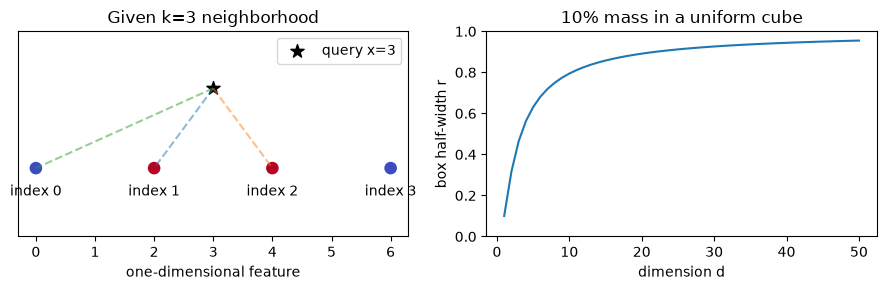

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
demo_coordinates = np.array([0., 2., 4., 6.])
axes[0].scatter(demo_coordinates, np.zeros(4), c=[0,1,1,0], cmap='coolwarm', s=65)
axes[0].scatter([3], [.35], marker='*', color='black', s=100, label='query x=3')
for index in [1,2,0]:
    axes[0].plot([3, demo_coordinates[index]], [.35, 0], '--', alpha=.5)
for index, coordinate in enumerate(demo_coordinates):
    axes[0].text(coordinate, -.12, f'index {index}', ha='center')
axes[0].set(xlabel='one-dimensional feature', ylim=(-.3,.6), yticks=[], title='Given k=3 neighborhood'); axes[0].legend()
demo_dimensions = np.arange(1, 51)
demo_halfwidth = .1**(1/demo_dimensions)
axes[1].plot(demo_dimensions, demo_halfwidth)
axes[1].set(xlabel='dimension d', ylabel='box half-width r', title='10% mass in a uniform cube', ylim=(0,1))
fig.tight_layout(); plt.show()

### Exercise 02.02.11 — Investigate smoothing in regression

**Type:** Experimental · **Answer:** Code

Generate 80 training coordinates uniform on [−2,2], targets sin(2x) plus Gaussian noise standard deviation .2, seed 210. Plot predictions for k=1,5,15 on a 201-point grid. Report grid MSE against the known noiseless function and explain how that differs from noisy-response prediction risk.

**Expected outcome:** actual curves and a model-specific smoothing interpretation, without asserting one k is always best.

In [ ]:
# Your code for Exercise 02.02.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.11**

Use the same training rows for every k. The grid's noiseless targets are a synthetic oracle, not another observed noisy dataset.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.11**

This depends on `knn_regress` and its helpers. Grid error describes this retained realization and the specified grid measure. Expected error for a fresh noisy response also includes its noise contribution under the stated independent additive model.

~~~python
rng = np.random.default_rng(210)
X = rng.uniform(-2, 2, (80,1)); y = np.sin(2*X[:,0])+rng.normal(0,.2,80)
query = np.linspace(-2,2,201)[:,None]; truth = np.sin(2*query[:,0])
plt.scatter(X[:,0], y, s=12, alpha=.4)
for k in (1,5,15):
    prediction = knn_regress(X,y,query,k)
    print(k, 'noiseless grid MSE', np.mean((prediction-truth)**2))
    plt.plot(query[:,0], prediction, label=f'k={k}')
plt.plot(query[:,0],truth,'k--',label='generating function')
plt.xlabel('x'); plt.ylabel('prediction'); plt.legend(); plt.show()
~~~

</details>

### Exercise 02.02.12 — Add irrelevant coordinates under controlled conditions

**Type:** Experimental · **Answer:** Code

Generate one (300,32) standard-normal feature matrix, seed 211, with labels drawn from sigmoid(3x₀). Keep the same labels and rows while comparing dimensions 2,8,32, fixed k=5, first 180 training rows and 120 validation rows. Fit scaling on training rows only. Record error, prediction time, and working-block settings.

**Expected outcome:** paired exploratory comparisons and a limitation statement about one data realization.

In [ ]:
# Your code for Exercise 02.02.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.12**

Use prefixes of one matrix instead of generating unrelated datasets for each dimension.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.12**

This depends on `knn_classify`. The added coordinates are irrelevant by construction. Their effect depends on sample size, metric, k, and realization. Validation results here are exploratory; do not claim a final untouched test evaluation or a theorem that all added dimensions harm performance.

~~~python
from time import perf_counter
rng = np.random.default_rng(211); X = rng.normal(size=(300,32))
labels = rng.binomial(1,1/(1+np.exp(-3*X[:,0])))
for dimension in (2,8,32):
    train, held = X[:180,:dimension], X[180:,:dimension]
    mean, scale = train.mean(axis=0), train.std(axis=0)
    start = perf_counter()
    prediction = knn_classify((train-mean)/scale,labels[:180],(held-mean)/scale,5)[0]
    print(dimension,'validation error / seconds',np.mean(prediction != labels[180:]),perf_counter()-start)
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 02.02.13 — Repair an invalid neighbor benchmark

**Type:** Critical · **Answer:** Markdown

A benchmark normalizes all rows together, selects k on test accuracy, ignores query latency, and reports unqualified probability estimates from k=1. Write a repaired protocol and list which claims the original evidence cannot support.

**Expected outcome:** fold-local fitting, validation boundaries, honest computation accounting, and probability-quality checks.

**Your response to Exercise 02.02.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.13**

Storing an example can move work from fitting to prediction; it does not remove that work.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.13**

Use training-only CV for k and transforms, freeze selected fitting and weighting policies, and evaluate once on untouched test rows. Record both storage/fitting and per-query/batch search time/memory. Evaluate probability losses and calibration separately from accuracy, documenting zero class-score support rather than silently clipping. A k=1 vote is usually a point-mass local estimate, not demonstrated certainty. Match preprocessing, splits, and selection/work budgets when comparing algorithms.

</details>

### Exercise 02.02.14 — Connect hard retrieval to differentiable learning

**Type:** Critical · **Answer:** Markdown

With fixed stored rows, uniform 1NN class scores are constant inside regions with the same selected neighbor. What does this imply for ordinary gradients with respect to query coordinates? Does it prove learned retrieval representations are impossible?

**Expected outcome:** identify piecewise constancy and discontinuities, while separating search from the objective used to learn an embedding.

**Your response to Exercise 02.02.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.14**

Changing a hard index is not the same operation as differentiating a smooth distance or contrastive objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.14**

Away from decision boundaries, the uniform fixed-neighbor class-score vector has zero query derivative; at a boundary it can be discontinuous. Differentiating only that hard output therefore does not supply a useful ordinary gradient for shaping the representation. This does not rule out learned retrieval: one can train representations with differentiable objectives, use smooth neighbor weighting, or specify another estimator. Those are additional algorithms whose objectives and derivatives need independent analysis. Inverse-distance regression with fixed nonzero neighbors has different local differentiability from uniform hard classification.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.02.15 — Interpret a large-sample nearest-neighbor result

**Type:** Mathematical · **Answer:** Markdown

Read Cover and Hart (1967), the binary-risk derivation in Section VI. If a fresh label and an idealized infinitely close neighbor label are independent Bernoulli(η) conditional on x, derive their mismatch probability. Compare η=.3 with the Bayes conditional error. Explain why this does not guarantee a bound for an arbitrary finite training set.

**Expected outcome:** an exact two-label calculation, a source/assumption note, and a bounded interpretation using the paper-study template.

**Your response to Exercise 02.02.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.02.15**

Enumerate (0,1) and (1,0). Passing to a nearby-neighbor limit requires the paper's sampling/regularity conditions.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.02.15**

Mismatch probability is (1−η)η+η(1−η)=2η(1−η). At η=.3 it is .42, versus Bayes error min(.3,.7)=.3. Under the paper's large-sample conditions, the binary limiting risk is E[2r*(X)(1−r*(X))] and is at most 2R*(1−R*) by the variance/Jensen relation. This concerns a limit of expected risks with stated iid and regularity assumptions; a finite neighborhood may have a different posterior and a finite test estimate has sampling error. The conditional two-label calculation is a component study, not a complete reproduction of the theorem or a certificate of a particular dataset's accuracy.

</details>

## 9. Summary and next learning steps

Explain the chosen geometry and sampling assumptions; derive local risk minimizers; implement deterministic bounded-memory search; independently verify distances, weights, labels, and validation; evaluate smoothing/dimension/work tradeoffs; critique claims beyond the experiment.

Continue to generative classifiers when published; the [stage guide](README.md) records readiness. Revisit [probability, information, and decisions](probability-information-and-decisions.ipynb) for conditional risk and probability support. Later representation/retrieval units change the feature geometry and search scale while retaining the need for honest evaluation.

Primary reading: [Cover and Hart, Nearest Neighbor Pattern Classification (1967), Section VI](https://isl.stanford.edu/~cover/papers/transIT/0021cove.pdf). Record notation, limit assumptions, local question, and departures in the [paper-study template](../../docs/paper-study-template.md). Required experiments use only generated local data and NumPy.